In [9]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from itertools import combinations

df = pd.read_csv("P2_698052.csv")
print(df.shape)
print(df.isna().sum())

(1002, 25)
Y      0
E1     0
E2     0
E3     0
E4     0
G1     0
G2     0
G3     0
G4     0
G5     0
G6     0
G7     0
G8     0
G9     0
G10    0
G11    0
G12    0
G13    0
G14    0
G15    0
G16    0
G17    0
G18    0
G19    0
G20    0
dtype: int64


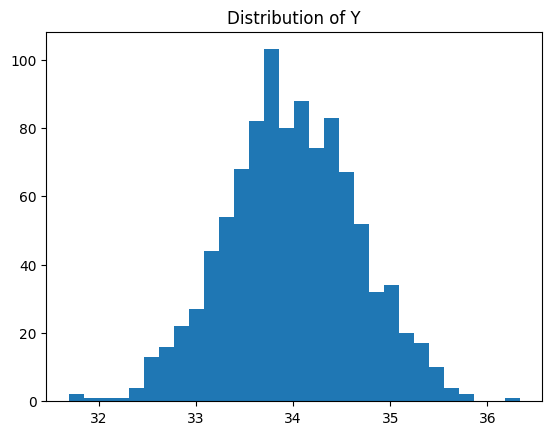

In [2]:
import matplotlib.pyplot as plt

plt.hist(df["Y"], bins=30)
plt.title("Distribution of Y")
plt.show()

#y is normally distributed

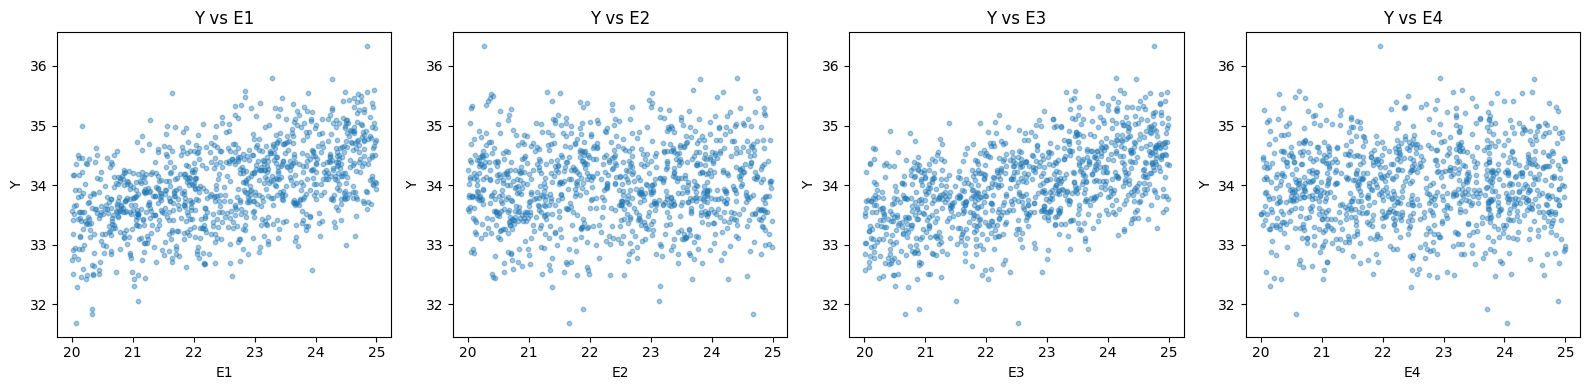

In [3]:
e_vars = ['E1', 'E2', 'E3', 'E4']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, e in enumerate(e_vars):
    axes[i].scatter(df[e], df['Y'], alpha=0.4, s=10)
    axes[i].set_xlabel(e)
    axes[i].set_ylabel('Y')
    axes[i].set_title(f'Y vs {e}')

plt.tight_layout()
plt.savefig('scatterplots_Y_vs_E.png', dpi=150)
plt.show()

#plotting e vs y

In [4]:
correlations = df.corr()['Y'].drop('Y')  # drop Y vs Y (always 1.0)
correlations_sorted = correlations.reindex(correlations.abs().sort_values(ascending=False).index)

print(correlations_sorted)

#correlation of each variable

E3     0.539673
E1     0.503658
G6     0.120862
G19    0.110534
G10   -0.064549
G9     0.058362
G17   -0.053400
E2     0.045495
E4     0.038620
G8     0.038057
G4     0.037030
G11   -0.036325
G13   -0.030599
G5    -0.028663
G15    0.025274
G14    0.019416
G18   -0.017484
G1     0.015512
G12   -0.012135
G3     0.011954
G16   -0.009424
G7     0.007360
G2    -0.003061
G20    0.000811
Name: Y, dtype: float64


In [5]:
feature_cols = ['E1', 'E2', 'E3', 'E4',
                'G1',  'G2',  'G3',  'G4',  'G5',
                'G6',  'G7',  'G8',  'G9',  'G10',
                'G11', 'G12', 'G13', 'G14', 'G15',
                'G16', 'G17', 'G18', 'G19', 'G20']

X = sm.add_constant(df[feature_cols])  #adds the intercept column
Y = df['Y']

#fits regression
model = sm.OLS(Y, X).fit()

#bonferonni
n_tests = len(feature_cols)

results = pd.DataFrame({
    'coefficient': model.params,
    'raw_pvalue':  model.pvalues,
    'bonferroni_pvalue': (model.pvalues * n_tests).clip(upper=1.0)
}).drop('const')  #drop the intercept row

results_sorted = results.sort_values('bonferroni_pvalue')

print(results_sorted.to_string())

#regression with all variables and their p values

     coefficient     raw_pvalue  bonferroni_pvalue
E3      0.248684  6.549084e-109      1.571780e-107
E1      0.234627   5.678988e-99       1.362957e-97
G6      0.177234   1.201751e-09       2.884202e-08
G19     0.166141   2.282903e-08       5.478968e-07
G10    -0.083777   4.172395e-03       1.001375e-01
G1     -0.006494   8.235616e-01       1.000000e+00
E2      0.004997   6.104160e-01       1.000000e+00
G2     -0.021284   4.626438e-01       1.000000e+00
G4      0.054389   5.914148e-02       1.000000e+00
G3     -0.008491   7.689923e-01       1.000000e+00
G7      0.015573   5.898583e-01       1.000000e+00
G5     -0.027194   3.519876e-01       1.000000e+00
G8      0.022376   4.400756e-01       1.000000e+00
G9      0.058812   4.387545e-02       1.000000e+00
G11    -0.023114   4.199336e-01       1.000000e+00
E4      0.010971   2.674268e-01       1.000000e+00
G12    -0.030200   2.973337e-01       1.000000e+00
G13    -0.029785   3.035265e-01       1.000000e+00
G15     0.027100   3.532093e-01

In [6]:
#interaction terms

sig_vars = ['E3', 'E1', 'G6', 'G19']

#pariwise interaction columns
for v1, v2 in combinations(sig_vars, 2):
    col_name = f'{v1}_x_{v2}'
    df[col_name] = df[v1] * df[v2]
    print(f"Created: {col_name}")


interaction_cols = [f'{v1}_x_{v2}' for v1, v2 in combinations(sig_vars, 2)]
all_cols = sig_vars + interaction_cols

X = sm.add_constant(df[all_cols])
Y = df['Y']

model = sm.OLS(Y, X).fit()

# bonferroni correction
n_tests = len(all_cols)

results = pd.DataFrame({
    'coefficient': model.params,
    'raw_pvalue': model.pvalues,
    'bonferroni_pvalue': (model.pvalues * n_tests).clip(upper=1.0)
}).drop('const')

print(results.sort_values('bonferroni_pvalue').to_string())

Created: E3_x_E1
Created: E3_x_G6
Created: E3_x_G19
Created: E1_x_G6
Created: E1_x_G19
Created: G6_x_G19
          coefficient  raw_pvalue  bonferroni_pvalue
G6_x_G19     0.271236    0.000005           0.000054
E3           0.067104    0.662649           1.000000
G6          -0.926258    0.147597           1.000000
E1           0.071796    0.642244           1.000000
E3_x_E1      0.007392    0.275112           1.000000
E3_x_G6      0.016310    0.416491           1.000000
E3_x_G19     0.007456    0.709978           1.000000
G19          0.468925    0.455932           1.000000
E1_x_G6      0.024967    0.214333           1.000000
E1_x_G19    -0.027895    0.169722           1.000000


In [7]:
sig_main = ['E3', 'E1', 'G19', 'G6']
sig_interactions = ['G6_x_G19']  # the ones that survived Bonferroni

final_cols = sig_main + sig_interactions

X_final = sm.add_constant(df[final_cols])
Y = df['Y']

final_model = sm.OLS(Y, X_final).fit()
print(final_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.575
Model:                            OLS   Adj. R-squared:                  0.573
Method:                 Least Squares   F-statistic:                     269.8
Date:                Wed, 06 May 2026   Prob (F-statistic):          2.40e-182
Time:                        02:42:09   Log-Likelihood:                -602.58
No. Observations:                1002   AIC:                             1217.
Df Residuals:                     996   BIC:                             1247.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         22.9100      0.311     73.745      0.0

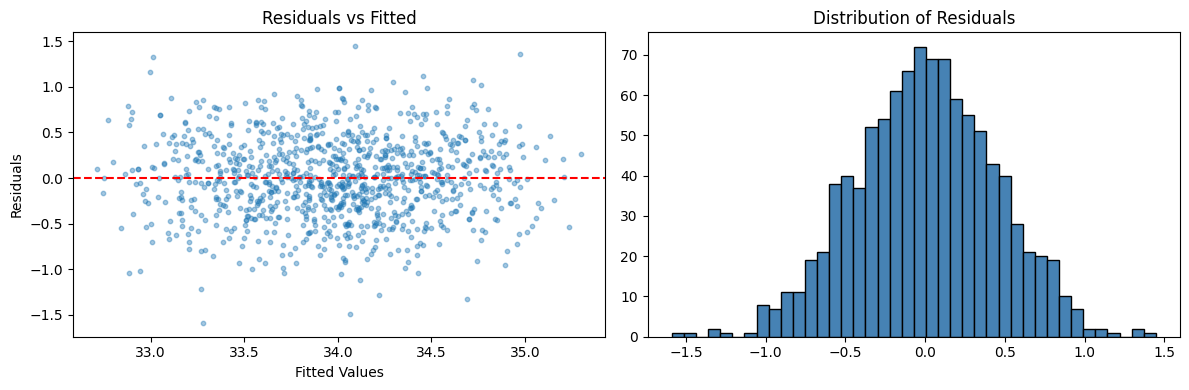

In [8]:
residuals = final_model.resid
fitted = final_model.fittedvalues

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(fitted, residuals, alpha=0.4, s=10)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')

plt.subplot(1, 2, 2)
plt.hist(residuals, bins=40, color='steelblue', edgecolor='black')
plt.title('Distribution of Residuals')

plt.tight_layout()
plt.savefig('residual_plots.png', dpi=150)
plt.show()

#Checking residuals